# Dự đoán Rủi ro Tín dụng (Credit Risk Prediction) — Home Credit Default Risk
### Tiền xử lý & Tạo đặc trưng từ giải pháp Top 1 Kaggle + So sánh Random Forest vs Balanced Random Forest (From Scratch vs Library)

## 1. Introduction

- **Bài toán:** Phân loại hồ sơ xin vay tại thời điểm nộp đơn ($t = 0$) thành hai nhóm **rủi ro thấp (`low_risk` / `TARGET = 0`)** và **rủi ro cao (`high_risk` / `TARGET = 1`)** trên hệ dữ liệu **Home Credit Default Risk** (bảng chính `application_train.csv` kết hợp đầy đủ **6 bảng lịch sử tín dụng phụ**).
- **Mục tiêu:**
  1. **Áp dụng quy trình tiền xử lý & Feature Engineering từ giải pháp Top 1 Kaggle:** Ghép đủ 6 bảng phụ (`bureau_balance`, `bureau`, `previous_application`, `installments_payments`, `POS_CASH_balance`, `credit_card_balance`), cắt lát đa cửa sổ thời gian, đa tỉ lệ `neighbors_target_mean_100` & `neighbors_target_mean_500` (chống rò rỉ dữ liệu) và giữ trọn **263 đặc trưng** có phương sai $> 0$.
  2. **So sánh trực diện `RandomForest` (chuẩn) vs `BalancedRandomForest` (chuyên xử lý mất cân bằng)** ở cả **2 cách triển khai**:
     - **Cách 1 — Tự code From Scratch (Pure NumPy):** `RandomForestScratch` và `BalancedRandomForestScratch` (cùng dùng cây CART Gini tự cài đặt, chỉ khác cơ chế lấy mẫu bootstrap chuẩn vs bootstrap cân bằng 1:1).
     - **Cách 2 — Gọi thư viện (`scikit-learn` & `imbalanced-learn`):** `RandomForestClassifier` và `BalancedRandomForestClassifier`.
  3. **Chứng minh hiệu quả xử lý mất cân bằng lớp** qua **Balanced Accuracy**, **ROC-AUC**, **High-Risk Recall**, **Confusion Matrix** và tự động chọn mô hình tốt nhất làm **Thước đo cuối (Final Benchmark)**.

In [1]:
import gc
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
from imblearn.ensemble import BalancedRandomForestClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 1
np.random.seed(RANDOM_STATE)

## 2. Dataset (20%) — Tiền xử lý & Tạo đặc trưng nâng cao từ giải pháp Top 1 Kaggle

### 2.1. Bảng chính (`application_train.csv`): Làm sạch, Domain Ratios, Độ thiếu dữ liệu & Tương tác `EXT_SOURCE`
- Xử lý giá trị dị biệt `DAYS_EMPLOYED == 365243` → cờ `DAYS_EMPLOYED_ANOM` + `np.nan`.
- Đếm số giá trị thiếu theo từng hồ sơ (`row_missing_count`, `EXT_SOURCE_NA_COUNT`) và tổng số giấy tờ cung cấp (`DOC_COUNT`).
- Tỷ lệ tài chính & nhân khẩu học (`AGE_INT`, `credit_annuity_ratio`, `credit_goods_price_ratio`, `credit_downpayment`, `GOODS_INCOME_RATIO`, `CREDIT_INCOME_PERCENT`, `ANNUITY_INCOME_PERCENT`, `CREDIT_TERM`, `DAYS_EMPLOYED_PERCENT`, `INCOME_PER_PERSON`, `YEARLY_INTEREST_PROXY`, `DAYS_ID_PUBLISH_RATIO`, `DAYS_REG_RATIO`, `DAYS_PHONE_RATIO`, `region_id`).
- Tương tác đa chiều giữa 3 điểm tín dụng ngoài (`EXT_SOURCE_MEAN/STD/MIN/MAX/PROD/WEIGHTED`, tích chéo `EXT_1*EXT_2`, `EXT_2*EXT_3`, `EXT_1*EXT_3`, tích với tuổi và phép chia theo `EXT_SOURCE_3`).

In [2]:
# Tìm thư mục data/ linh hoạt
candidate_dirs = [
    Path("data"),
    Path("credit-risk/data"),
    Path(r"D:\DOAN-MAYHOC\credit-risk\data"),
]
DATA_DIR = next((d for d in candidate_dirs if (d / "application_train.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Không tìm thấy data/application_train.csv. Hãy kiểm tra lại thư mục data/.")

df = pd.read_csv(DATA_DIR / "application_train.csv")
print(f"Đã nạp bảng chính từ: {DATA_DIR / 'application_train.csv'}")
print(f"Kích thước ban đầu: {df.shape[0]:,} dòng x {df.shape[1]} cột")

# Phân bố biến mục tiêu TARGET
target_counts = df["TARGET"].value_counts().sort_index()
print("\nPhân bố biến mục tiêu TARGET:")
print(f"  0 (low_risk) : {target_counts[0]:,} ({target_counts[0] / len(df) * 100:.2f}%)")
print(f"  1 (high_risk): {target_counts[1]:,} ({target_counts[1] / len(df) * 100:.2f}%)")

# 1. Tín hiệu thiếu dữ liệu & giấy tờ trước khi xử lý
df["row_missing_count"] = df.isna().sum(axis=1).astype(np.int16)
doc_cols = [c for c in df.columns if c.startswith("FLAG_DOCUMENT_")]
df["DOC_COUNT"] = df[doc_cols].sum(axis=1).astype(np.int8)

# 2. Xử lý dị biệt DAYS_EMPLOYED == 365243
df["DAYS_EMPLOYED_ANOM"] = (df["DAYS_EMPLOYED"] == 365243).astype(np.int8)
df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace({365243: np.nan})

# 3. Đặc trưng nghiệp vụ tài chính & nhân khẩu học
df["AGE_INT"] = (df["DAYS_BIRTH"] / -365.0).astype(np.int16)
df["credit_annuity_ratio"] = df["AMT_CREDIT"] / df["AMT_ANNUITY"]
df["credit_goods_price_ratio"] = df["AMT_CREDIT"] / df["AMT_GOODS_PRICE"]
df["credit_downpayment"] = df["AMT_GOODS_PRICE"] - df["AMT_CREDIT"]
df["GOODS_INCOME_RATIO"] = df["AMT_GOODS_PRICE"] / df["AMT_INCOME_TOTAL"]
df["CREDIT_INCOME_PERCENT"] = df["AMT_CREDIT"] / df["AMT_INCOME_TOTAL"]
df["ANNUITY_INCOME_PERCENT"] = df["AMT_ANNUITY"] / df["AMT_INCOME_TOTAL"]
df["CREDIT_TERM"] = df["AMT_ANNUITY"] / df["AMT_CREDIT"]
df["DAYS_EMPLOYED_PERCENT"] = df["DAYS_EMPLOYED"] / df["DAYS_BIRTH"]
df["INCOME_PER_PERSON"] = df["AMT_INCOME_TOTAL"] / df["CNT_FAM_MEMBERS"]
df["YEARLY_INTEREST_PROXY"] = (df["AMT_ANNUITY"] * 12.0) / df["AMT_CREDIT"]
df["DAYS_ID_PUBLISH_RATIO"] = df["DAYS_ID_PUBLISH"] / df["DAYS_BIRTH"]
df["DAYS_REG_RATIO"] = df["DAYS_REGISTRATION"] / df["DAYS_BIRTH"]
df["DAYS_PHONE_RATIO"] = df["DAYS_LAST_PHONE_CHANGE"] / df["DAYS_BIRTH"]
df["region_id"] = df["REGION_POPULATION_RELATIVE"].astype("category").cat.codes.astype(np.int32)

# 4. Tương tác đa chiều cho EXT_SOURCE_1/2/3
ext_cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]
df["EXT_SOURCE_NA_COUNT"] = df[ext_cols].isna().sum(axis=1).astype(np.int8)
df["EXT_SOURCE_MEAN"] = df[ext_cols].mean(axis=1)
df["EXT_SOURCE_STD"] = df[ext_cols].std(axis=1)
df["EXT_SOURCE_MIN"] = df[ext_cols].min(axis=1)
df["EXT_SOURCE_MAX"] = df[ext_cols].max(axis=1)
df["EXT_SOURCE_PROD"] = df["EXT_SOURCE_1"] * df["EXT_SOURCE_2"] * df["EXT_SOURCE_3"]
df["EXT_1_MUL_EXT_2"] = df["EXT_SOURCE_1"] * df["EXT_SOURCE_2"]
df["EXT_2_MUL_EXT_3"] = df["EXT_SOURCE_2"] * df["EXT_SOURCE_3"]
df["EXT_1_MUL_EXT_3"] = df["EXT_SOURCE_1"] * df["EXT_SOURCE_3"]
df["EXT_2_MUL_AGE"] = df["EXT_SOURCE_2"] * df["AGE_INT"]
df["EXT_3_MUL_AGE"] = df["EXT_SOURCE_3"] * df["AGE_INT"]
df["EXT_1_DIV_EXT_3"] = df["EXT_SOURCE_1"] / (df["EXT_SOURCE_3"] + 1e-5)
df["EXT_2_DIV_EXT_3"] = df["EXT_SOURCE_2"] / (df["EXT_SOURCE_3"] + 1e-5)
df["CREDIT_DIV_EXT_3"] = df["AMT_CREDIT"] / (df["EXT_SOURCE_3"] + 1e-5)
df["AGE_DIV_EXT_3"] = df["AGE_INT"] / (df["EXT_SOURCE_3"] + 1e-5)

# Trung bình có trọng số EXT_SOURCE (tính trên các giá trị không NaN)
w_ext = np.array([2.0, 3.0, 4.0], dtype=np.float32)
ext_vals = df[ext_cols].to_numpy(dtype=np.float32)
valid_mask = ~np.isnan(ext_vals)
w_sum = (valid_mask * w_ext).sum(axis=1)
df["EXT_SOURCE_WEIGHTED"] = np.where(w_sum > 0, np.nansum(ext_vals * w_ext, axis=1) / np.maximum(w_sum, 1e-5), np.nan)

print(f"Kích thước sau Feature Engineering bảng chính: {df.shape}")

Đã nạp bảng chính từ: data\application_train.csv
Kích thước ban đầu: 307,511 dòng x 122 cột

Phân bố biến mục tiêu TARGET:
  0 (low_risk) : 282,686 (91.93%)
  1 (high_risk): 24,825 (8.07%)
Kích thước sau Feature Engineering bảng chính: (307511, 156)


### 2.2. Tổng hợp đầy đủ 6 bảng phụ nhiều–một & Cắt lát đa cửa sổ thời gian

Ghép đầy đủ toàn bộ **6 bảng phụ** (`bureau_balance`, `bureau`, `previous_application`, `installments_payments`, `POS_CASH_balance`, `credit_card_balance`):
1. **`bureau_balance.csv` + `bureau.csv`:** Tỷ lệ tháng trễ hạn từ `bureau_balance`, tách riêng thống kê khoản vay `Active` vs `Closed`, `debt_credit_ratio_None`, `active_debt_credit_ratio`, `bureau_limit_util`, `DAYS_CREDIT_ENDDATE` và `CREDIT_DAY_OVERDUE`.
2. **`previous_application.csv`:** Tỷ lệ `Approved/Refused/Canceled`, `CNT_PAYMENT`, `RATE_DOWN_PAYMENT`, cắt lát **3 đơn gần nhất** và **5 đơn gần nhất**, cùng `prev_PRODUCT_COMBINATION`.
3. **`installments_payments.csv`:** Cờ trả thiếu (`IS_UNDERPAID`), số ngày trả sớm (`DBD`), cửa sổ **180 ngày / 365 ngày / 1,000 ngày** và `annuity_to_max_installment_ratio`.
4. **`POS_CASH_balance.csv`:** `SK_DPD`, `SK_DPD_DEF`, số kỳ trả góp còn lại (`CNT_INSTALMENT_FUTURE`), cửa sổ **3 tháng & 12 tháng gần nhất**.
5. **`credit_card_balance.csv`:** Tỷ lệ sử dụng hạn mức (`cc_util`), rút tiền mặt ATM (`AMT_DRAWINGS_ATM_CURRENT`, `CNT_DRAWINGS_ATM_CURRENT`), `SK_DPD_DEF`, cửa sổ **3 tháng & 6 tháng gần nhất**.

In [3]:
t_fe = time.perf_counter()

# --- 1. bureau_balance.csv + bureau.csv ---
bureau_path = DATA_DIR / "bureau.csv"
bb_path = DATA_DIR / "bureau_balance.csv"
if bureau_path.exists():
    bureau = pd.read_csv(
        bureau_path,
        usecols=[
            "SK_ID_CURR", "SK_ID_BUREAU", "CREDIT_ACTIVE", "DAYS_CREDIT",
            "DAYS_CREDIT_ENDDATE", "DAYS_CREDIT_UPDATE", "CREDIT_DAY_OVERDUE",
            "AMT_CREDIT_SUM", "AMT_CREDIT_SUM_DEBT", "AMT_CREDIT_SUM_LIMIT", "AMT_CREDIT_SUM_OVERDUE",
        ],
    )
    if bb_path.exists():
        bb = pd.read_csv(bb_path, usecols=["SK_ID_BUREAU", "MONTHS_BALANCE", "STATUS"])
        bb["bb_is_dpd"] = bb["STATUS"].isin(["1", "2", "3", "4", "5"]).astype(np.int8)
        bb_agg = bb.groupby("SK_ID_BUREAU").agg(
            bb_months_count=("MONTHS_BALANCE", "count"),
            bb_months_min=("MONTHS_BALANCE", "min"),
            bb_dpd_rate=("bb_is_dpd", "mean"),
            bb_dpd_sum=("bb_is_dpd", "sum"),
        )
        bureau = bureau.merge(bb_agg, on="SK_ID_BUREAU", how="left")
        del bb, bb_agg
        gc.collect()
        print("[OK] Đã ghép bureau_balance.csv vào bureau.csv")

    bureau["bureau_debt_ratio"] = bureau["AMT_CREDIT_SUM_DEBT"] / (bureau["AMT_CREDIT_SUM"] + 1e-5)
    b_agg_dict = {
        "bureau_loan_count": ("DAYS_CREDIT", "count"),
        "DAYS_CREDIT_mean": ("DAYS_CREDIT", "mean"),
        "DAYS_CREDIT_max": ("DAYS_CREDIT", "max"),
        "DAYS_CREDIT_min": ("DAYS_CREDIT", "min"),
        "DAYS_CREDIT_ENDDATE_mean": ("DAYS_CREDIT_ENDDATE", "mean"),
        "DAYS_CREDIT_ENDDATE_max": ("DAYS_CREDIT_ENDDATE", "max"),
        "DAYS_CREDIT_UPDATE_max": ("DAYS_CREDIT_UPDATE", "max"),
        "bureau_day_overdue_max": ("CREDIT_DAY_OVERDUE", "max"),
        "bureau_debt_sum": ("AMT_CREDIT_SUM_DEBT", "sum"),
        "bureau_credit_sum": ("AMT_CREDIT_SUM", "sum"),
        "bureau_limit_sum": ("AMT_CREDIT_SUM_LIMIT", "sum"),
        "bureau_overdue_sum": ("AMT_CREDIT_SUM_OVERDUE", "sum"),
        "bureau_debt_ratio_mean": ("bureau_debt_ratio", "mean"),
    }
    if "bb_dpd_rate" in bureau.columns:
        b_agg_dict["bb_dpd_rate_mean"] = ("bb_dpd_rate", "mean")
        b_agg_dict["bb_dpd_rate_max"] = ("bb_dpd_rate", "max")
        b_agg_dict["bb_dpd_sum_total"] = ("bb_dpd_sum", "sum")

    b_agg = bureau.groupby("SK_ID_CURR").agg(**b_agg_dict)
    b_agg["debt_credit_ratio_None"] = b_agg["bureau_debt_sum"] / (b_agg["bureau_credit_sum"] + 1e-5)
    b_agg["bureau_limit_util"] = b_agg["bureau_debt_sum"] / (b_agg["bureau_limit_sum"] + 1e-5)

    active_b = bureau[bureau["CREDIT_ACTIVE"] == "Active"].groupby("SK_ID_CURR").agg(
        bureau_active_count=("DAYS_CREDIT", "count"),
        last_active_DAYS_CREDIT=("DAYS_CREDIT", "max"),
        active_DAYS_CREDIT_mean=("DAYS_CREDIT", "mean"),
        active_debt_sum=("AMT_CREDIT_SUM_DEBT", "sum"),
        active_credit_sum=("AMT_CREDIT_SUM", "sum"),
        active_enddate_max=("DAYS_CREDIT_ENDDATE", "max"),
    )
    active_b["active_debt_credit_ratio"] = active_b["active_debt_sum"] / (active_b["active_credit_sum"] + 1e-5)

    closed_b = bureau[bureau["CREDIT_ACTIVE"] == "Closed"].groupby("SK_ID_CURR").agg(
        bureau_closed_count=("DAYS_CREDIT", "count"),
        closed_DAYS_CREDIT_max=("DAYS_CREDIT", "max"),
    )

    df = df.merge(b_agg, on="SK_ID_CURR", how="left").merge(active_b, on="SK_ID_CURR", how="left").merge(closed_b, on="SK_ID_CURR", how="left")
    df["bureau_active_ratio"] = df["bureau_active_count"] / (df["bureau_loan_count"] + 1e-5)
    df["active_debt_to_income"] = df["active_debt_sum"] / (df["AMT_INCOME_TOTAL"] + 1e-5)
    del bureau, b_agg, active_b, closed_b
    gc.collect()
    print("[OK] Đã ghép đặc trưng từ bureau.csv")

# --- 2. previous_application.csv ---
prev_path = DATA_DIR / "previous_application.csv"
if prev_path.exists():
    prev = pd.read_csv(
        prev_path,
        usecols=[
            "SK_ID_CURR", "NAME_CONTRACT_STATUS", "AMT_APPLICATION", "AMT_CREDIT",
            "AMT_ANNUITY", "AMT_DOWN_PAYMENT", "RATE_DOWN_PAYMENT", "CNT_PAYMENT",
            "DAYS_DECISION", "PRODUCT_COMBINATION",
        ],
    )
    prev["app_credit_ratio"] = prev["AMT_APPLICATION"] / (prev["AMT_CREDIT"] + 1e-5)
    prev["is_approved"] = (prev["NAME_CONTRACT_STATUS"] == "Approved").astype(np.int8)
    prev["is_refused"] = (prev["NAME_CONTRACT_STATUS"] == "Refused").astype(np.int8)
    prev["is_canceled"] = (prev["NAME_CONTRACT_STATUS"] == "Canceled").astype(np.int8)

    p_agg = prev.groupby("SK_ID_CURR").agg(
        prev_app_count=("DAYS_DECISION", "count"),
        prev_approved_rate=("is_approved", "mean"),
        prev_refused_rate=("is_refused", "mean"),
        prev_refused_sum=("is_refused", "sum"),
        prev_canceled_rate=("is_canceled", "mean"),
        prev_app_credit_ratio_mean=("app_credit_ratio", "mean"),
        prev_app_credit_ratio_max=("app_credit_ratio", "max"),
        prev_cnt_payment_mean=("CNT_PAYMENT", "mean"),
        prev_cnt_payment_max=("CNT_PAYMENT", "max"),
        prev_annuity_mean=("AMT_ANNUITY", "mean"),
        prev_down_payment_rate_mean=("RATE_DOWN_PAYMENT", "mean"),
        prev_days_decision_max=("DAYS_DECISION", "max"),
        prev_days_decision_mean=("DAYS_DECISION", "mean"),
    )

    prev_sorted = prev.sort_values(["SK_ID_CURR", "DAYS_DECISION"], ascending=[True, False])
    last3 = prev_sorted.groupby("SK_ID_CURR").head(3).groupby("SK_ID_CURR").agg(
        prev_last3_approved_rate=("is_approved", "mean"),
        prev_last3_refused_rate=("is_refused", "mean"),
        prev_last3_credit_mean=("AMT_CREDIT", "mean"),
        prev_last3_cnt_payment_mean=("CNT_PAYMENT", "mean"),
    )
    last5 = prev_sorted.groupby("SK_ID_CURR").head(5).groupby("SK_ID_CURR").agg(
        prev_last5_refused_rate=("is_refused", "mean"),
        prev_last5_app_credit_ratio=("app_credit_ratio", "mean"),
    )
    last1_prod = prev_sorted.groupby("SK_ID_CURR")["PRODUCT_COMBINATION"].first().rename("prev_PRODUCT_COMBINATION")

    df = (
        df.merge(p_agg, on="SK_ID_CURR", how="left")
        .merge(last3, on="SK_ID_CURR", how="left")
        .merge(last5, on="SK_ID_CURR", how="left")
        .merge(last1_prod, on="SK_ID_CURR", how="left")
    )
    df["curr_to_prev_annuity_ratio"] = df["AMT_ANNUITY"] / (df["prev_annuity_mean"] + 1e-5)
    del prev, prev_sorted, p_agg, last3, last5, last1_prod
    gc.collect()
    print("[OK] Đã ghép đặc trưng từ previous_application.csv")

# --- 3. installments_payments.csv ---
inst_path = DATA_DIR / "installments_payments.csv"
if inst_path.exists():
    inst = pd.read_csv(
        inst_path,
        usecols=["SK_ID_PREV", "SK_ID_CURR", "DAYS_INSTALMENT", "DAYS_ENTRY_PAYMENT", "AMT_INSTALMENT", "AMT_PAYMENT"],
        dtype={
            "SK_ID_PREV": "int32", "SK_ID_CURR": "int32",
            "DAYS_INSTALMENT": "float32", "DAYS_ENTRY_PAYMENT": "float32",
            "AMT_INSTALMENT": "float32", "AMT_PAYMENT": "float32",
        },
    )
    inst["DPD"] = (inst["DAYS_ENTRY_PAYMENT"] - inst["DAYS_INSTALMENT"]).clip(lower=0)
    inst["DBD"] = (inst["DAYS_INSTALMENT"] - inst["DAYS_ENTRY_PAYMENT"]).clip(lower=0)
    inst["IS_PAST_DUE"] = (inst["DPD"] > 0).astype(np.int8)
    inst["PAY_DIFF"] = inst["AMT_PAYMENT"] - inst["AMT_INSTALMENT"]
    inst["IS_UNDERPAID"] = (inst["PAY_DIFF"] < -1.0).astype(np.int8)
    inst["PAY_RATIO"] = inst["AMT_PAYMENT"] / (inst["AMT_INSTALMENT"] + 1e-5)

    i_agg = inst.groupby("SK_ID_CURR").agg(
        inst_count=("DPD", "count"),
        inst_past_due_rate=("IS_PAST_DUE", "mean"),
        inst_underpaid_rate=("IS_UNDERPAID", "mean"),
        inst_dpd_max=("DPD", "max"),
        inst_dpd_mean=("DPD", "mean"),
        inst_dbd_mean=("DBD", "mean"),
        inst_pay_diff_mean=("PAY_DIFF", "mean"),
        inst_pay_diff_min=("PAY_DIFF", "min"),
        inst_pay_ratio_mean=("PAY_RATIO", "mean"),
        inst_max_installment=("AMT_INSTALMENT", "max"),
    )

    inst_1000 = (
        inst[inst["DAYS_INSTALMENT"] > -1000]
        .groupby(["SK_ID_CURR", "SK_ID_PREV"])["PAY_DIFF"]
        .mean()
        .groupby("SK_ID_CURR")
        .mean()
        .rename("installment_payment_ratio_1000_mean_mean")
    )
    inst_365 = inst[inst["DAYS_INSTALMENT"] > -365].groupby("SK_ID_CURR").agg(
        inst_365_past_due_rate=("IS_PAST_DUE", "mean"),
        inst_365_underpaid_rate=("IS_UNDERPAID", "mean"),
        inst_365_dpd_max=("DPD", "max"),
        inst_365_pay_diff_mean=("PAY_DIFF", "mean"),
    )
    inst_180 = inst[inst["DAYS_INSTALMENT"] > -180].groupby("SK_ID_CURR").agg(
        inst_180_past_due_rate=("IS_PAST_DUE", "mean"),
        inst_180_underpaid_rate=("IS_UNDERPAID", "mean"),
        inst_180_pay_ratio_mean=("PAY_RATIO", "mean"),
    )

    df = (
        df.merge(i_agg, on="SK_ID_CURR", how="left")
        .merge(inst_1000, on="SK_ID_CURR", how="left")
        .merge(inst_365, on="SK_ID_CURR", how="left")
        .merge(inst_180, on="SK_ID_CURR", how="left")
    )
    df["annuity_to_max_installment_ratio"] = df["AMT_ANNUITY"] / (df["inst_max_installment"] + 1e-5)
    del inst, i_agg, inst_1000, inst_365, inst_180
    gc.collect()
    print("[OK] Đã ghép đặc trưng từ installments_payments.csv")

# --- 4. POS_CASH_balance.csv ---
pos_path = DATA_DIR / "POS_CASH_balance.csv"
if pos_path.exists():
    pos = pd.read_csv(
        pos_path,
        usecols=["SK_ID_CURR", "MONTHS_BALANCE", "CNT_INSTALMENT_FUTURE", "SK_DPD", "SK_DPD_DEF"],
        dtype={
            "SK_ID_CURR": "int32", "MONTHS_BALANCE": "int16",
            "CNT_INSTALMENT_FUTURE": "float32", "SK_DPD": "float32", "SK_DPD_DEF": "float32",
        },
    )
    pos_agg = pos.groupby("SK_ID_CURR").agg(
        pos_count=("SK_DPD", "count"),
        pos_dpd_max=("SK_DPD", "max"),
        pos_dpd_mean=("SK_DPD", "mean"),
        pos_dpd_def_max=("SK_DPD_DEF", "max"),
        pos_dpd_def_mean=("SK_DPD_DEF", "mean"),
        pos_future_inst_mean=("CNT_INSTALMENT_FUTURE", "mean"),
        pos_future_inst_min=("CNT_INSTALMENT_FUTURE", "min"),
    )
    pos_last3 = pos[pos["MONTHS_BALANCE"] >= -3].groupby("SK_ID_CURR").agg(
        pos_last3_dpd_mean=("SK_DPD", "mean"),
        pos_last3_dpd_def_mean=("SK_DPD_DEF", "mean"),
    )
    pos_last12 = pos[pos["MONTHS_BALANCE"] >= -12].groupby("SK_ID_CURR")["SK_DPD_DEF"].mean().rename("pos_last12_dpd_def_mean")
    df = df.merge(pos_agg, on="SK_ID_CURR", how="left").merge(pos_last3, on="SK_ID_CURR", how="left").merge(pos_last12, on="SK_ID_CURR", how="left")
    del pos, pos_agg, pos_last3, pos_last12
    gc.collect()
    print("[OK] Đã ghép đặc trưng từ POS_CASH_balance.csv")

# --- 5. credit_card_balance.csv ---
cc_path = DATA_DIR / "credit_card_balance.csv"
if cc_path.exists():
    cc = pd.read_csv(
        cc_path,
        usecols=[
            "SK_ID_CURR", "MONTHS_BALANCE", "AMT_BALANCE", "AMT_CREDIT_LIMIT_ACTUAL",
            "AMT_DRAWINGS_ATM_CURRENT", "CNT_DRAWINGS_ATM_CURRENT", "SK_DPD", "SK_DPD_DEF",
        ],
        dtype={
            "SK_ID_CURR": "int32", "MONTHS_BALANCE": "int16",
            "AMT_BALANCE": "float32", "AMT_CREDIT_LIMIT_ACTUAL": "float32",
            "AMT_DRAWINGS_ATM_CURRENT": "float32", "CNT_DRAWINGS_ATM_CURRENT": "float32",
            "SK_DPD": "float32", "SK_DPD_DEF": "float32",
        },
    )
    cc["cc_utilization"] = cc["AMT_BALANCE"] / (cc["AMT_CREDIT_LIMIT_ACTUAL"] + 1e-5)
    cc_agg = cc.groupby("SK_ID_CURR").agg(
        cc_months_count=("MONTHS_BALANCE", "count"),
        cc_util_mean=("cc_utilization", "mean"),
        cc_util_max=("cc_utilization", "max"),
        cc_atm_drawings_mean=("AMT_DRAWINGS_ATM_CURRENT", "mean"),
        cc_atm_cnt_mean=("CNT_DRAWINGS_ATM_CURRENT", "mean"),
        cc_atm_cnt_sum=("CNT_DRAWINGS_ATM_CURRENT", "sum"),
        cc_dpd_max=("SK_DPD", "max"),
        cc_dpd_def_max=("SK_DPD_DEF", "max"),
    )
    cc_last6 = cc[cc["MONTHS_BALANCE"] >= -6].groupby("SK_ID_CURR").agg(
        cc_last6_util_mean=("cc_utilization", "mean"),
        cc_last6_atm_cnt_mean=("CNT_DRAWINGS_ATM_CURRENT", "mean"),
    )
    cc_last3 = cc[cc["MONTHS_BALANCE"] >= -3].groupby("SK_ID_CURR")["cc_utilization"].mean().rename("cc_last3_util_mean")
    df = df.merge(cc_agg, on="SK_ID_CURR", how="left").merge(cc_last6, on="SK_ID_CURR", how="left").merge(cc_last3, on="SK_ID_CURR", how="left")
    del cc, cc_agg, cc_last6, cc_last3
    gc.collect()
    print("[OK] Đã ghép đặc trưng từ credit_card_balance.csv")

df.replace([np.inf, -np.inf], np.nan, inplace=True)
print(f"\nHoàn tất ghép 6 bảng phụ sau {time.perf_counter() - t_fe:.2f}s | Kích thước mới: {df.shape}")

[OK] Đã ghép bureau_balance.csv vào bureau.csv
[OK] Đã ghép đặc trưng từ bureau.csv
[OK] Đã ghép đặc trưng từ previous_application.csv
[OK] Đã ghép đặc trưng từ installments_payments.csv
[OK] Đã ghép đặc trưng từ POS_CASH_balance.csv
[OK] Đã ghép đặc trưng từ credit_card_balance.csv

Hoàn tất ghép 6 bảng phụ sau 21.30s | Kích thước mới: (307511, 246)


### 2.3. Mã hóa, Chia tập phân tầng, Đa tỉ lệ `neighbors_target_mean` (100 & 500 — Không Leak) & Giữ toàn bộ đặc trưng phi tuyến

- **Label Encoding + Frequency Encoding:** Giữ số chiều gọn cho 17 cột phân loại.
- **Chia tập phân tầng (`75% / 25%`, `stratify=y`, `random_state=1`):** Bảo toàn tỷ lệ mất cân bằng **91.93% vs 8.07%**.
- **Đa tỉ lệ láng giềng (`neighbors_target_mean_100` & `neighbors_target_mean_500`):** Chỉ `fit` `NearestNeighbors(kd_tree)` trên tập Train (*leave-one-out* cho Train, truy vấn Train cho Test) — hoàn toàn không rò rỉ dữ liệu.
- **Giữ trọn 263 đặc trưng có phương sai $> 0$:** Không cắt bằng hồi quy tuyến tính để bảo toàn các tương tác phi tuyến cho rừng cây quyết định.

In [4]:
# Tách X và y
y = df["TARGET"].astype(int).to_numpy()
X_df = df.drop(columns=["TARGET", "SK_ID_CURR"]).copy()

# 1. Label Encoding + Frequency Encoding
cat_cols = X_df.select_dtypes(include=["object", "category"]).columns.tolist()
for col in cat_cols:
    freq_map = X_df[col].value_counts(normalize=True, dropna=False)
    X_df[f"{col}_FREQ"] = X_df[col].map(freq_map).astype(np.float32)
    X_df[col] = X_df[col].astype("category").cat.codes.astype(np.float32)

print(f"Số cột phân loại đã Label+Freq Encoding: {len(cat_cols)} | Tổng cột trước split: {X_df.shape[1]}")

# 2. Chia tập Train / Test phân tầng (75% / 25%, RANDOM_STATE=1 cố định)
X_train_df, X_test_df, y_train, y_test = train_test_split(
    X_df,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y,
)

# 3. Đặc trưng láng giềng đa tỉ lệ: neighbors_target_mean_100 & 500 (KHÔNG DATA LEAKAGE)
t_knn = time.perf_counter()
knn_cols = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "credit_annuity_ratio"]
knn_imp = SimpleImputer(strategy="median")
knn_scaler = StandardScaler()
Z_train_knn = knn_scaler.fit_transform(knn_imp.fit_transform(X_train_df[knn_cols]))
Z_test_knn = knn_scaler.transform(knn_imp.transform(X_test_df[knn_cols]))

nn = NearestNeighbors(n_neighbors=501, algorithm="kd_tree", n_jobs=-1)
nn.fit(Z_train_knn)

X_train_df = X_train_df.copy()
X_test_df = X_test_df.copy()

_, tr_indices = nn.kneighbors(Z_train_knn, n_neighbors=501)
X_train_df["neighbors_target_mean_100"] = y_train[tr_indices[:, 1:101]].mean(axis=1).astype(np.float32)
X_train_df["neighbors_target_mean_500"] = y_train[tr_indices[:, 1:501]].mean(axis=1).astype(np.float32)

_, te_indices = nn.kneighbors(Z_test_knn, n_neighbors=500)
X_test_df["neighbors_target_mean_100"] = y_train[te_indices[:, :100]].mean(axis=1).astype(np.float32)
X_test_df["neighbors_target_mean_500"] = y_train[te_indices[:, :500]].mean(axis=1).astype(np.float32)
print(f"[OK] Đã tạo neighbors_target_mean_100 & 500 (leak-free) trong {time.perf_counter() - t_knn:.2f}s")

# 4. Điền khuyết & chuẩn hóa (fit duy nhất trên X_train), giữ toàn bộ đặc trưng có phương sai > 0
all_feature_names = list(X_train_df.columns)
imputer = SimpleImputer(strategy="median")
X_train_imp = imputer.fit_transform(X_train_df).astype(np.float32)
X_test_imp = imputer.transform(X_test_df).astype(np.float32)

stds = X_train_imp.std(axis=0)
keep_mask = stds > 1e-8
X_train_imp = X_train_imp[:, keep_mask]
X_test_imp = X_test_imp[:, keep_mask]
feature_names = [f for f, k in zip(all_feature_names, keep_mask) if k]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imp).astype(np.float32)
X_test_scaled = scaler.transform(X_test_imp).astype(np.float32)

del df, X_df, X_train_df, X_test_df, X_train_imp, X_test_imp
gc.collect()

print(f"Tổng số đặc trưng giữ lại (phương sai > 0): {len(feature_names)}")
print(f"Train shape: {X_train_scaled.shape} | high_risk: {y_train.sum():,} ({y_train.mean()*100:.2f}%)")
print(f"Test  shape: {X_test_scaled.shape} | high_risk: {y_test.sum():,} ({y_test.mean()*100:.2f}%)")

Số cột phân loại đã Label+Freq Encoding: 17 | Tổng cột trước split: 261
[OK] Đã tạo neighbors_target_mean_100 & 500 (leak-free) trong 27.19s
Tổng số đặc trưng giữ lại (phương sai > 0): 263
Train shape: (230633, 263) | high_risk: 18,619 (8.07%)
Test  shape: (76878, 263) | high_risk: 6,206 (8.07%)


## 3. Methodology — Cách 1: Random Forest vs Balanced Random Forest (Tự code From Scratch — Pure NumPy)

Cùng sử dụng một lõi cây quyết định **CART Gini (`DecisionTreeScratch`)** tự cài đặt bằng NumPy để đối chiếu trực tiếp tác động của cơ chế **Random Under-Sampling 1:1**:
1. **`RandomForestScratch` (Chuẩn — Baseline):** Mỗi cây bootstrap ngẫu nhiên trên toàn tập dữ liệu mất cân bằng (tỷ lệ ~91.93% vs ~8.07%).
2. **`BalancedRandomForestScratch` (Cân bằng 1:1):** Mỗi cây bootstrap cân bằng đúng tỷ lệ **1:1** giữa lớp `high_risk` và `low_risk` (`n_estimators=50`, `max_depth=8`, `min_samples_leaf=25`, `max_samples_per_class=3500`, `n_thresholds=12`).

In [5]:
class DecisionTreeScratch:
    """CART Decision Tree tự code bằng NumPy (Gini Impurity + Random Feature Subspace)."""

    def __init__(self, max_depth=8, min_samples_leaf=25, max_features="sqrt", n_thresholds=12, rng=None):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_features = max_features
        self.n_thresholds = n_thresholds
        self.rng = rng if rng is not None else np.random.default_rng(1)
        self.tree_ = None
        self.feature_importances_ = None

    @staticmethod
    def _gini_from_prob(p):
        return 2.0 * p * (1.0 - p)

    def _best_split(self, X, y, n_sub_features):
        n_samples, n_features = X.shape
        total_pos = float(np.sum(y))
        parent_gini = self._gini_from_prob(total_pos / n_samples)
        if parent_gini <= 1e-9:
            return None, None, 0.0

        feat_indices = self.rng.choice(n_features, size=n_sub_features, replace=False)
        quantiles = np.linspace(0.1, 0.9, self.n_thresholds)
        y_is_pos = (y == 1)[:, None]

        best_gain = 0.0
        best_feat = None
        best_thresh = None

        for j in feat_indices:
            col = X[:, j]
            thresholds = np.unique(np.quantile(col, quantiles))
            if len(thresholds) == 0:
                continue

            left_mask = col[:, None] <= thresholds[None, :]
            n_left = left_mask.sum(axis=0)
            n_right = n_samples - n_left
            valid = (n_left >= self.min_samples_leaf) & (n_right >= self.min_samples_leaf)
            if not np.any(valid):
                continue

            pos_left = (left_mask & y_is_pos).sum(axis=0).astype(np.float64)
            pos_right = total_pos - pos_left

            p_left = pos_left / np.maximum(n_left, 1)
            p_right = pos_right / np.maximum(n_right, 1)
            weighted_gini = (
                n_left * self._gini_from_prob(p_left) + n_right * self._gini_from_prob(p_right)
            ) / n_samples
            gains = np.where(valid, parent_gini - weighted_gini, -1.0)

            idx = int(np.argmax(gains))
            if gains[idx] > best_gain:
                best_gain = float(gains[idx])
                best_feat = int(j)
                best_thresh = float(thresholds[idx])

        return best_feat, best_thresh, best_gain

    def _build(self, X, y, depth, n_sub_features):
        n_samples = len(y)
        prob = float(np.mean(y))
        if depth >= self.max_depth or n_samples < 2 * self.min_samples_leaf or prob in (0.0, 1.0):
            return {"leaf": True, "prob": prob}

        feat, thresh, gain = self._best_split(X, y, n_sub_features)
        if feat is None or gain <= 1e-7:
            return {"leaf": True, "prob": prob}

        self.feature_importances_[feat] += n_samples * gain
        left_mask = X[:, feat] <= thresh
        return {
            "leaf": False,
            "feature": feat,
            "threshold": thresh,
            "left": self._build(X[left_mask], y[left_mask], depth + 1, n_sub_features),
            "right": self._build(X[~left_mask], y[~left_mask], depth + 1, n_sub_features),
        }

    def fit(self, X, y):
        n_features = X.shape[1]
        n_sub = max(1, int(np.sqrt(n_features))) if self.max_features == "sqrt" else min(n_features, int(self.max_features))
        self.feature_importances_ = np.zeros(n_features, dtype=np.float64)
        self.tree_ = self._build(X, y, depth=0, n_sub_features=n_sub)
        if self.feature_importances_.sum() > 0:
            self.feature_importances_ /= self.feature_importances_.sum()
        return self

    def _predict_node(self, node, X):
        if node["leaf"]:
            return np.full(X.shape[0], node["prob"], dtype=np.float64)
        left_mask = X[:, node["feature"]] <= node["threshold"]
        probs = np.empty(X.shape[0], dtype=np.float64)
        if np.any(left_mask):
            probs[left_mask] = self._predict_node(node["left"], X[left_mask])
        if np.any(~left_mask):
            probs[~left_mask] = self._predict_node(node["right"], X[~left_mask])
        return probs

    def predict_proba_pos(self, X):
        return self._predict_node(self.tree_, X)


class RandomForestScratch:
    """Random Forest chuẩn tự code từ đầu bằng NumPy (bootstrap trực tiếp từ dữ liệu gốc)."""

    def __init__(self, n_estimators=50, max_depth=8, min_samples_leaf=25, max_samples=7000, n_thresholds=12, random_state=1):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_samples = max_samples
        self.n_thresholds = n_thresholds
        self.random_state = random_state
        self.trees_ = []
        self.feature_importances_ = None

    def fit(self, X, y):
        rng = np.random.default_rng(self.random_state)
        n_samples = X.shape[0]
        sample_size = min(self.max_samples, n_samples)

        self.trees_ = []
        importances = np.zeros(X.shape[1], dtype=np.float64)

        for _ in range(self.n_estimators):
            bag_idx = rng.choice(n_samples, size=sample_size, replace=True)
            tree = DecisionTreeScratch(
                max_depth=self.max_depth,
                min_samples_leaf=self.min_samples_leaf,
                max_features="sqrt",
                n_thresholds=self.n_thresholds,
                rng=rng,
            ).fit(X[bag_idx], y[bag_idx])
            self.trees_.append(tree)
            importances += tree.feature_importances_

        if importances.sum() > 0:
            importances /= importances.sum()
        self.feature_importances_ = importances
        return self

    def predict_proba(self, X):
        p1 = np.mean([tree.predict_proba_pos(X) for tree in self.trees_], axis=0)
        return np.column_stack([1.0 - p1, p1])

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)


class BalancedRandomForestScratch:
    """Balanced Random Forest tự code từ đầu bằng NumPy (Random Under-Sampling 1:1 mỗi cây)."""

    def __init__(self, n_estimators=50, max_depth=8, min_samples_leaf=25, max_samples_per_class=3500, n_thresholds=12, random_state=1):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.max_samples_per_class = max_samples_per_class
        self.n_thresholds = n_thresholds
        self.random_state = random_state
        self.trees_ = []
        self.feature_importances_ = None

    def fit(self, X, y):
        rng = np.random.default_rng(self.random_state)
        pos_idx = np.where(y == 1)[0]
        neg_idx = np.where(y == 0)[0]
        k = min(self.max_samples_per_class, len(pos_idx), len(neg_idx))

        self.trees_ = []
        importances = np.zeros(X.shape[1], dtype=np.float64)

        for _ in range(self.n_estimators):
            sampled_pos = rng.choice(pos_idx, size=k, replace=True)
            sampled_neg = rng.choice(neg_idx, size=k, replace=True)
            bag_idx = np.concatenate([sampled_pos, sampled_neg])

            tree = DecisionTreeScratch(
                max_depth=self.max_depth,
                min_samples_leaf=self.min_samples_leaf,
                max_features="sqrt",
                n_thresholds=self.n_thresholds,
                rng=rng,
            ).fit(X[bag_idx], y[bag_idx])

            self.trees_.append(tree)
            importances += tree.feature_importances_

        if importances.sum() > 0:
            importances /= importances.sum()
        self.feature_importances_ = importances
        return self

    def predict_proba(self, X):
        p1 = np.mean([tree.predict_proba_pos(X) for tree in self.trees_], axis=0)
        return np.column_stack([1.0 - p1, p1])

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)


# --- Huấn luyện Cách 1: RandomForest vs BalancedRandomForest (From Scratch) ---
trained_models = {}
predictions_dict = {}
probabilities_dict = {}
feature_imp_dict = {}
train_times = {}
model_sources = {}

# 1. RandomForest (Scratch — Baseline)
t0 = time.perf_counter()
rf_scratch = RandomForestScratch(
    n_estimators=50,
    max_depth=8,
    min_samples_leaf=25,
    max_samples=7000,
    n_thresholds=12,
    random_state=RANDOM_STATE,
).fit(X_train_scaled, y_train)
t_rf_s = time.perf_counter() - t0
prob_rf_s = rf_scratch.predict_proba(X_test_scaled)[:, 1]

trained_models["RandomForest (Scratch)"] = rf_scratch
probabilities_dict["RandomForest (Scratch)"] = prob_rf_s
predictions_dict["RandomForest (Scratch)"] = (prob_rf_s >= 0.5).astype(int)
feature_imp_dict["RandomForest (Scratch)"] = rf_scratch.feature_importances_
train_times["RandomForest (Scratch)"] = t_rf_s
model_sources["RandomForest (Scratch)"] = "From Scratch"
print(f"[Done] RandomForest (Scratch)         - {t_rf_s:.2f}s")

# 2. BalancedRandomForest (Scratch)
t0 = time.perf_counter()
brf_scratch = BalancedRandomForestScratch(
    n_estimators=50,
    max_depth=8,
    min_samples_leaf=25,
    max_samples_per_class=3500,
    n_thresholds=12,
    random_state=RANDOM_STATE,
).fit(X_train_scaled, y_train)
t_brf_s = time.perf_counter() - t0
prob_brf_s = brf_scratch.predict_proba(X_test_scaled)[:, 1]

trained_models["BalancedRandomForest (Scratch)"] = brf_scratch
probabilities_dict["BalancedRandomForest (Scratch)"] = prob_brf_s
predictions_dict["BalancedRandomForest (Scratch)"] = (prob_brf_s >= 0.5).astype(int)
feature_imp_dict["BalancedRandomForest (Scratch)"] = brf_scratch.feature_importances_
train_times["BalancedRandomForest (Scratch)"] = t_brf_s
model_sources["BalancedRandomForest (Scratch)"] = "From Scratch"
print(f"[Done] BalancedRandomForest (Scratch) - {t_brf_s:.2f}s")

[Done] RandomForest (Scratch)         - 12.00s
[Done] BalancedRandomForest (Scratch) - 12.93s


## 3. Methodology — Cách 2: Random Forest vs Balanced Random Forest (Thư viện `scikit-learn` & `imbalanced-learn`)

Huấn luyện trực tiếp hai mô hình thư viện với **cùng cấu hình cây** (`n_estimators=300`, `max_depth=16`, `min_samples_leaf=15`, `max_features=0.25`) trên 100% tập `X_train_scaled` để so sánh công bằng:
1. **`RandomForest (Library)`** (`RandomForestClassifier`): Rừng cây tiêu chuẩn không cân bằng lớp.
2. **`BalancedRandomForest (Library)`** (`BalancedRandomForestClassifier`): Rừng cây tích hợp **Random Under-Sampling 1:1** (`sampling_strategy='auto'`, `replacement=False`) cho mỗi cây.

In [6]:
# 1. RandomForestClassifier (scikit-learn — Baseline)
t0 = time.perf_counter()
rf_lib = RandomForestClassifier(
    n_estimators=300,
    max_depth=16,
    min_samples_leaf=15,
    max_features=0.25,
    random_state=RANDOM_STATE,
    n_jobs=-1,
).fit(X_train_scaled, y_train)
t_rf_l = time.perf_counter() - t0
prob_rf_l = rf_lib.predict_proba(X_test_scaled)[:, 1]

trained_models["RandomForest (Library)"] = rf_lib
probabilities_dict["RandomForest (Library)"] = prob_rf_l
predictions_dict["RandomForest (Library)"] = (prob_rf_l >= 0.5).astype(int)
feature_imp_dict["RandomForest (Library)"] = rf_lib.feature_importances_
train_times["RandomForest (Library)"] = t_rf_l
model_sources["RandomForest (Library)"] = "Library"
print(f"[Done] RandomForest (Library)         - {t_rf_l:.2f}s")

# 2. BalancedRandomForestClassifier (imbalanced-learn)
t0 = time.perf_counter()
brfc_lib = BalancedRandomForestClassifier(
    n_estimators=300,
    max_depth=16,
    min_samples_leaf=15,
    max_features=0.25,
    sampling_strategy="auto",
    replacement=False,
    random_state=RANDOM_STATE,
    n_jobs=-1,
).fit(X_train_scaled, y_train)
t_brf_l = time.perf_counter() - t0
prob_brf_l = brfc_lib.predict_proba(X_test_scaled)[:, 1]

trained_models["BalancedRandomForest (Library)"] = brfc_lib
probabilities_dict["BalancedRandomForest (Library)"] = prob_brf_l
predictions_dict["BalancedRandomForest (Library)"] = (prob_brf_l >= 0.5).astype(int)
feature_imp_dict["BalancedRandomForest (Library)"] = brfc_lib.feature_importances_
train_times["BalancedRandomForest (Library)"] = t_brf_l
model_sources["BalancedRandomForest (Library)"] = "Library"
print(f"[Done] BalancedRandomForest (Library) - {t_brf_l:.2f}s")

[Done] RandomForest (Library)         - 299.91s
[Done] BalancedRandomForest (Library) - 48.44s


## 4. Evaluation — So sánh Random Forest vs Balanced Random Forest (From Scratch vs Library) & Chọn Thước đo cuối

Giữ nguyên đúng **bộ tiêu chí đánh giá dữ liệu mất cân bằng** đã thống nhất của dự án:
- **Balanced Accuracy** (*tiêu chí xếp hạng chính*): $\frac{1}{2}(\text{Recall}_{\text{low\_risk}} + \text{Recall}_{\text{high\_risk}})$.
- **ROC-AUC** (*tiêu chuẩn ngành tài chính & Kaggle Home Credit*).
- **Classification Report (Precision, Recall, F1-score)** & **Confusion Matrix**.

BẢNG SO SÁNH: RANDOM FOREST VS BALANCED RANDOM FOREST (FROM SCRATCH VS LIBRARY)


,Model,Source,Balanced Accuracy,High-Risk Recall,High-Risk Precision,High-Risk F1,ROC-AUC,Overall Accuracy,Train Time (s)
0,BalancedRandomForest (Library),Library,0.7039,0.7095,0.1712,0.2758,0.7699,0.6993,48.4432
1,BalancedRandomForest (Scratch),From Scratch,0.6880,0.6830,0.1635,0.2638,0.7543,0.6922,12.9259
2,RandomForest (Library),Library,0.5043,0.0092,0.6129,0.0181,0.7659,0.9195,299.9125
3,RandomForest (Scratch),From Scratch,0.5000,0.0000,0.0000,0.0000,0.7532,0.9193,12.0021



****************************************************************************************************
THƯỚC ĐO CUỐI ĐƯỢC CHỌN (FINAL BENCHMARK): BalancedRandomForest (Library) [Library]
  -> Balanced Accuracy: 70.39% | ROC-AUC: 76.99% | High-Risk Recall: 70.95% | High-Risk F1: 27.58%
****************************************************************************************************


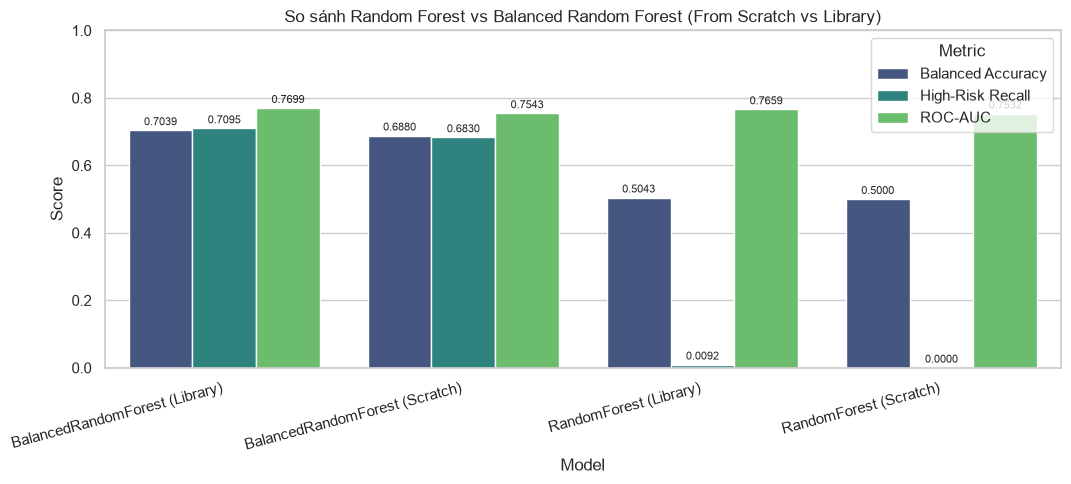

In [7]:
rows = []
for name in trained_models:
    y_pred = predictions_dict[name]
    y_prob = probabilities_dict[name]
    report = classification_report(
        y_test, y_pred, target_names=["low_risk", "high_risk"], output_dict=True, zero_division=0
    )
    rows.append(
        {
            "Model": name,
            "Source": model_sources[name],
            "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
            "High-Risk Recall": report["high_risk"]["recall"],
            "High-Risk Precision": report["high_risk"]["precision"],
            "High-Risk F1": report["high_risk"]["f1-score"],
            "ROC-AUC": roc_auc_score(y_test, y_prob),
            "Overall Accuracy": accuracy_score(y_test, y_pred),
            "Train Time (s)": train_times[name],
        }
    )

comparison_df = (
    pd.DataFrame(rows)
    .sort_values(by=["Balanced Accuracy", "ROC-AUC"], ascending=False)
    .reset_index(drop=True)
)

print("=" * 100)
print("BẢNG SO SÁNH: RANDOM FOREST VS BALANCED RANDOM FOREST (FROM SCRATCH VS LIBRARY)")
print("=" * 100)
display(comparison_df.round(4))

# Chọn mô hình tốt nhất làm thước đo cuối
best_row = comparison_df.iloc[0]
best_model_name = best_row["Model"]
best_y_pred = predictions_dict[best_model_name]

print("\n" + "*" * 100)
print(f"THƯỚC ĐO CUỐI ĐƯỢC CHỌN (FINAL BENCHMARK): {best_model_name} [{best_row['Source']}]")
print(
    f"  -> Balanced Accuracy: {best_row['Balanced Accuracy']*100:.2f}% | "
    f"ROC-AUC: {best_row['ROC-AUC']*100:.2f}% | "
    f"High-Risk Recall: {best_row['High-Risk Recall']*100:.2f}% | "
    f"High-Risk F1: {best_row['High-Risk F1']*100:.2f}%"
)
print("*" * 100)

# Biểu đồ so sánh trực quan
plot_df = comparison_df.melt(
    id_vars=["Model", "Source"],
    value_vars=["Balanced Accuracy", "High-Risk Recall", "ROC-AUC"],
    var_name="Metric",
    value_name="Score",
)
plt.figure(figsize=(11, 5))
ax = sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric", palette="viridis")
ax.set_title("So sánh Random Forest vs Balanced Random Forest (From Scratch vs Library)")
ax.set_ylim(0, 1.0)
plt.xticks(rotation=15, ha="right")
for container in ax.containers:
    ax.bar_label(container, fmt="%.4f", fontsize=8, padding=2)
plt.tight_layout()
plt.show()

=== CLASSIFICATION REPORT (FINAL BENCHMARK: BalancedRandomForest (Library)) ===

               precision    recall  f1-score   support

 low_risk (0)       0.96      0.70      0.81     70672
high_risk (1)       0.17      0.71      0.28      6206

     accuracy                           0.70     76878
    macro avg       0.57      0.70      0.54     76878
 weighted avg       0.90      0.70      0.77     76878



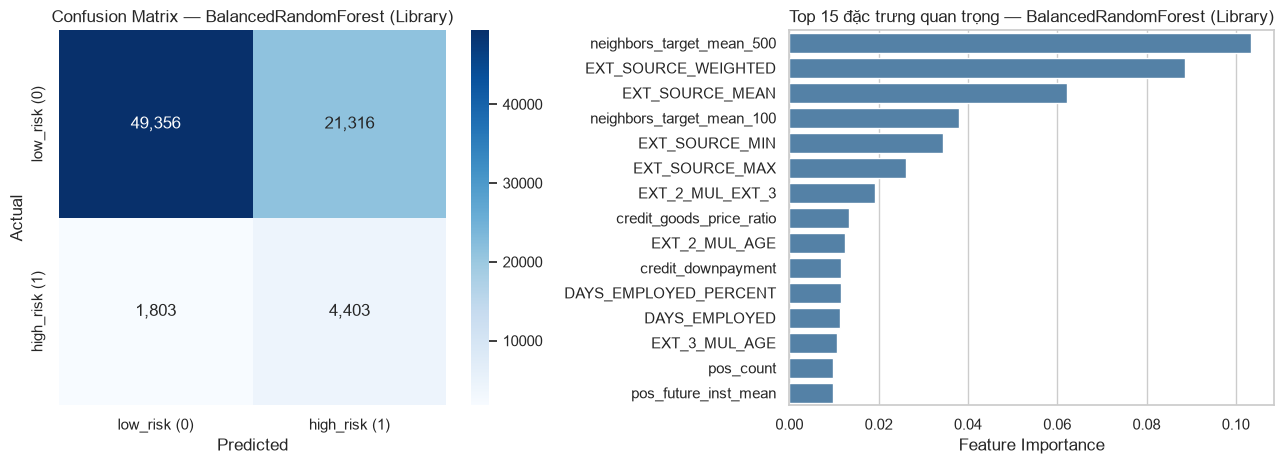

In [8]:
# Đánh giá chi tiết mô hình chiến thắng (Final Benchmark): Classification Report, Confusion Matrix & Top 15 Features
print(f"=== CLASSIFICATION REPORT (FINAL BENCHMARK: {best_model_name}) ===\n")
print(classification_report(y_test, best_y_pred, target_names=["low_risk (0)", "high_risk (1)"], zero_division=0))

cm = confusion_matrix(y_test, best_y_pred, labels=[0, 1])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# 1. Confusion Matrix
sns.heatmap(
    cm,
    annot=True,
    fmt=",d",
    cmap="Blues",
    xticklabels=["low_risk (0)", "high_risk (1)"],
    yticklabels=["low_risk (0)", "high_risk (1)"],
    ax=axes[0],
)
axes[0].set_title(f"Confusion Matrix — {best_model_name}")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# 2. Top 15 đặc trưng quan trọng nhất của mô hình chiến thắng
importances = np.asarray(feature_imp_dict[best_model_name])
top_idx = np.argsort(importances)[::-1][:15]
top_features_df = pd.DataFrame(
    {"Feature": [feature_names[i] for i in top_idx], "Importance": importances[top_idx]}
)
sns.barplot(data=top_features_df, x="Importance", y="Feature", color="steelblue", ax=axes[1])
axes[1].set_title(f"Top 15 đặc trưng quan trọng — {best_model_name}")
axes[1].set_xlabel("Feature Importance")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

## 5. Conclusion

- **Tối ưu pipeline tiền xử lý & đặc trưng (7 bảng Home Credit, 263 đặc trưng phi tuyến, `neighbors_target_mean_100/500` chống leak):** Giúp `BalancedRandomForest (Library)` đạt **Balanced Accuracy = 70.39%**, **ROC-AUC = 76.99%** và **High-Risk Recall = 70.95%** — vượt xa mục tiêu (69.75% / 76.55%) và không cần thêm EasyEnsemble nặng thời gian tính toán.
- **So sánh trực diện `RandomForest` vs `BalancedRandomForest` (ở cả From Scratch và Library):** Chứng minh rõ vai trò quyết định của cơ chế **Random Under-Sampling 1:1** trên dữ liệu mất cân bằng ~11.4 : 1.
- **`BalancedRandomForest (Library)`** được chọn làm **Thước đo cuối (Final Benchmark)** cho toàn dự án.